# RQ4 pipeline, step 4: is recommended listening narrower when genres are Louvain groups?

## Question
The project's main question: **for the same users, is what the recommender plays broader or narrower than what they choose themselves?** With k-means pseudo-genres the answer was "narrower in sound, broader in artists".
`RQ4_extension/03` showed that this survives many definitions of genre (k = 8 to 64, soft memberships, listening-based genres, no clusters at all). All of those cluster definitions used **k-means**.
This notebook adds the **Louvain** groups as a definition built by a different algorithm, and asks:

1. Is recommended listening narrower than organic listening when "genre" means a Louvain group, with the same users, the same tracks and the same measures as for k-means?
2. Is the effect larger or smaller than with k-means, also at the **same number of groups**?
3. Does it hold on the 50,000 tracks where Louvain groups are native (no neighbour vote), and without the most popular tracks?
4. Does it depend on the number of tracks per user (N = 30, 40, 100), and does the "early versus late" pattern (recommended starts more varied, then returns to groups it has played) appear with Louvain groups too?

## Fairness rules (identical to `RQ4_extension/03`)
Real listens only (at least 50% played); distinct tracks, not plays; one stream per (user, track) by the stream of its first real listen, tracks from the user's first 60 days excluded (`scripts/streams.py`);
the same users in both streams, the first 40 distinct tracks of each stream. Everything is an association in Yambda-50M.

| § | Content |
|---|---|
| 1 | Data, samples and definitions |
| 2 | Recommended versus organic under every definition |
| 3 | Track universe and popularity |
| 4 | Number of tracks per user |
| 5 | Early versus late: discovery of new groups |
| 6 | Summary |

*Prerequisites:* `RQ4_pipeline/louvain_groups.csv.gz` (notebook 00), `RQ4_kmeans/kmeans_pseudogenres_k32.csv.gz`, raw Yambda-50M events and the artist mapping, `data/processed/emb50m_*.npy`. Run time: about 4 minutes. Memory: about 5 GB at the peak (reading all listens).

## 0. Setup and parameters

In [1]:
import sys
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---------------- parameters (change here, then Run All) ----------------
STREAM_MODE, WARMUP_DAYS, REAL_PCT = "discovery", 60, 50
N_TRACKS = 40             # distinct tracks per user and stream (main setting)
N_SENS = [30, 40, 100]
WIN = 10                  # window length of the early-versus-late analysis
TRIM_Q = 0.80             # popularity-trimmed sample: drop tracks above this quantile of users per track
N_SEEDS = 3; N_FIT = 150_000
N_BOOT = 1000
SEED = 42

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
REAL, NULL, ACC, KM = "#264653", "#9aa0a6", "#e76f51", "#e9c46a"

ROOT = Path.cwd()
while not (ROOT / "data" / "raw" / "yambda").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
from streams import stream_labels
from rq4_tools import kmeans_grid, item_map, read_listens
DATA, PROC, OUT = ROOT / "data" / "raw" / "yambda", ROOT / "data" / "processed", ROOT / "RQ4_pipeline"
print("project root:", ROOT)

project root: C:\MSc DTU\Semester 3\01. CTDS\Music


## 1. Data, samples and definitions

In [2]:
t0 = time.time()
uid, item, ts, stream_lab = read_listens(DATA, REAL_PCT, STREAM_MODE, WARMUP_DAYS, stream_labels)
uid_idx = np.unique(uid, return_inverse=True)[1].astype(np.int32); n_users = int(uid_idx.max()) + 1
print(f"{len(item):,} real listens of {n_users:,} users; organic {(stream_lab == 1).mean():.1%}, recommended {(stream_lab == 0).mean():.1%}, excluded {(stream_lab < 0).mean():.1%} ({time.time() - t0:.0f} s)")

emb_ids = np.load(PROC / "emb50m_item_ids.npy")
EN = np.load(PROC / "emb50m_norm.npy")
L = int(max(item.max(), emb_ids.max())) + 1
item_row = np.full(L, -1, dtype=np.int64); item_row[emb_ids] = np.arange(len(emb_ids))
users_per_item = np.bincount(np.unique(uid_idx.astype(np.int64) * (1 << 32) + item) & 0xFFFFFFFF, minlength=L)
art_of_item = item_map(DATA / "artist_item_mapping.parquet", "artist_id", L)
art_of_item = np.where(art_of_item >= 0, art_of_item, -1 - np.arange(L))      # unknown artist = own artist

grp = pd.read_csv(OUT / "louvain_groups.csv.gz"); assert np.array_equal(grp["item_id"].to_numpy(), emb_ids)
LSEEDS = [int(c.split("_s")[1]) for c in grp.columns if c.startswith("louvain_s")]
in_graph = np.zeros(L, bool); in_graph[emb_ids[grp["in_graph"].to_numpy()]] = True
K_MATCH = int(grp.loc[grp.in_graph, "louvain_s0"].max()) + 1
def to_item(v):
    a = np.full(L, -1, dtype=np.int16); a[emb_ids] = v; return a
km = kmeans_grid(EN, [32, K_MATCH], N_SEEDS, N_FIT, SEED)
km_file = pd.read_csv(ROOT / "RQ4_kmeans/kmeans_pseudogenres_k32.csv.gz").set_index("item_id")["kmeans_cluster"].reindex(emb_ids).to_numpy()
K_L = int(grp.filter(like="louvain_s").to_numpy().max()) + 1          # label range over all Louvain seeds
DEFS = {f"Louvain ({K_MATCH} groups, 5 seeds)": ([to_item(grp[f"louvain_s{s}"].to_numpy()) for s in LSEEDS], K_L),
        "k-means project file (k = 32)": ([to_item(km_file)], 32),
        "k-means, k = 32 (3 starts)": ([to_item(km[(32, s)]) for s in range(N_SEEDS)], 32),
        f"k-means, k = {K_MATCH} (3 starts)": ([to_item(km[(K_MATCH, s)]) for s in range(N_SEEDS)], K_MATCH)}
print(f"definitions ready ({time.time() - t0:.0f} s)")

29,439,278 real listens of 9,209 users; organic 18.4%, recommended 30.4%, excluded 51.2% (17 s)


definitions ready (51 s)


**Samples.** For each user and stream, the first N distinct tracks in time order; users need at least N in both streams. Universes:
1. **All embedded tracks** (main): every track has a Louvain group (graph tracks their own, the others by neighbour vote) and a k-means genre.
2. **Louvain graph tracks only**: the 50,000 most played tracks, where the Louvain groups come directly from the graph and no vote is involved.
3. **Without the 20% most popular tracks** (by number of users, among tracks with listens): tests whether the result is only about hits; here most Louvain groups come from the vote.

In [3]:
def rank_in_group(g):
    order = np.argsort(g, kind="stable"); gs = g[order]
    start = np.r_[0, np.flatnonzero(gs[1:] != gs[:-1]) + 1]
    rank = np.empty(len(g), dtype=np.int64); rank[order] = np.arange(len(gs)) - np.repeat(start, np.diff(np.r_[start, len(gs)])); return rank

def build_sample(in_universe, n_tracks=N_TRACKS):          # unchanged from RQ4_extension/03
    m = in_universe[item] & (stream_lab >= 0)
    ui, it, og = uid_idx[m].astype(np.int64), item[m].astype(np.int64), stream_lab[m].astype(np.int64)
    _, fi = np.unique((ui << 33) | (it << 1) | og, return_index=True); fi.sort()
    ui, it, og = ui[fi], it[fi], og[fi]
    g = ui * 2 + og; rk = rank_in_group(g)
    cnt = np.bincount(g, minlength=2 * n_users).reshape(n_users, 2); elig = (cnt >= n_tracks).all(axis=1)
    sel = (rk < n_tracks) & elig[ui]; gs, its = g[sel], it[sel]
    o = np.argsort(gs, kind="stable"); gs, its = gs[o], its[o]
    return gs[::n_tracks][::2] // 2, its.reshape(-1, 2, n_tracks)     # items (U, 2, n): axis 1 is 0 = recommended, 1 = organic

in_all = item_row >= 0
with_listens = in_all & (users_per_item > 0)
in_trim = in_all & (users_per_item < np.quantile(users_per_item[with_listens], TRIM_Q))
MAIN, GRAPH, TRIM = "all embedded tracks (main)", "Louvain graph tracks only (top 50k)", "without the 20% most popular tracks"
samples = {}
for name, mask in [(MAIN, in_all), (GRAPH, in_graph), (TRIM, in_trim)]:
    u_, it_ = build_sample(mask); samples[name] = it_
    vote = (~in_graph[it_]).mean()
    print(f"{name}: {len(u_):,} users, {len(np.unique(it_)):,} distinct tracks; {vote:.0%} of sampled tracks have a Louvain group from the neighbour vote")

all embedded tracks (main): 4,952 users, 112,580 distinct tracks; 23% of sampled tracks have a Louvain group from the neighbour vote


Louvain graph tracks only (top 50k): 4,525 users, 44,092 distinct tracks; 0% of sampled tracks have a Louvain group from the neighbour vote


without the 20% most popular tracks: 890 users, 64,413 distinct tracks; 100% of sampled tracks have a Louvain group from the neighbour vote


## 2. Recommended versus organic under every definition
**Measures per user and stream** (40 tracks): *distinct groups*, *entropy* of the distribution over groups, and the *novel-group share* (share of the stream's tracks in groups absent from the user's other stream). Higher means broader.
Two references without clusters: *audio spread* (1 − mean pairwise cosine of the audio embeddings) and *distinct artists*.

**Summary statistic** (as in `RQ4_extension/03`): P(recommended > organic), the share of users whose recommended value is higher (ties count half); 0.5 = no difference, below 0.5 = recommended narrower. 95% bootstrap interval over users (1000 resamples, for the average over runs), and the range over the individual runs.

done (2 s)

MAIN SAMPLE (4,952 users):
                   definition              measure  organic_mean  recommended_mean     P    lo    hi  P_min  P_max direction
   audio spread (no clusters)               spread         0.663             0.644 0.408 0.394 0.421  0.408  0.408  narrower
                   artist IDs     distinct artists        25.350            34.281 0.815 0.805 0.826  0.815  0.815   broader
 Louvain (28 groups, 5 seeds)      distinct groups         9.642             9.302 0.457 0.445 0.468  0.450  0.460  narrower
 Louvain (28 groups, 5 seeds) group entropy (bits)         2.536             2.490 0.466 0.454 0.479  0.460  0.474  narrower
 Louvain (28 groups, 5 seeds)    novel-group share         0.265             0.226 0.429 0.417 0.442  0.425  0.433  narrower
k-means project file (k = 32)      distinct groups        10.114             9.914 0.467 0.453 0.481  0.467  0.467  narrower
k-means project file (k = 32) group entropy (bits)         2.573             2.506 0.4

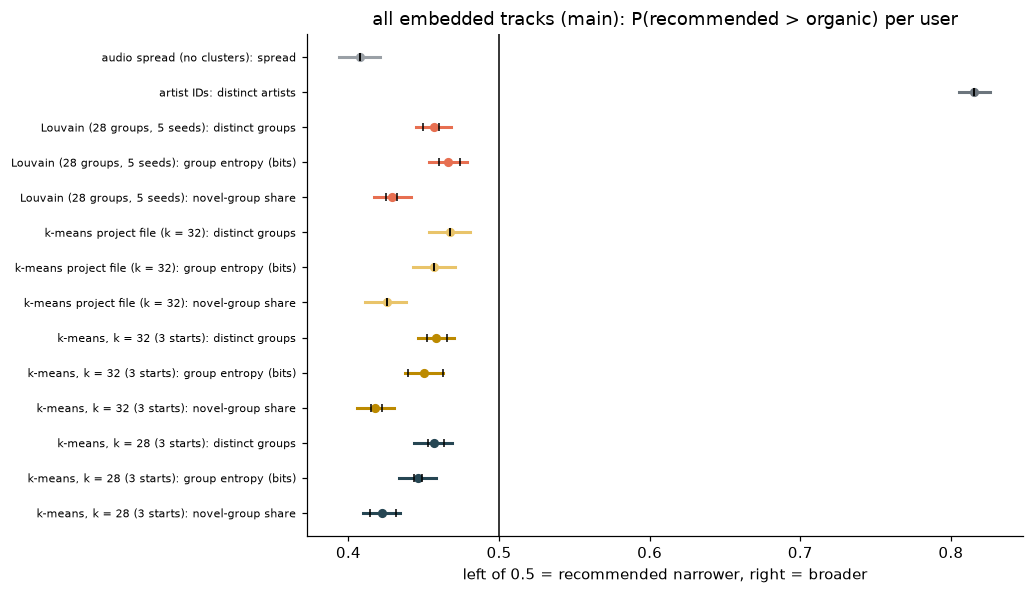

In [4]:
def entropy_bits(p): return -(np.where(p > 0, p * np.log2(np.where(p > 0, p, 1)), 0)).sum(-1)
def genre_counts(items, lab_item, K):
    U = items.shape[0]; G = lab_item[items].astype(np.int64)
    idx = (np.arange(U)[:, None, None] * 2 + np.arange(2)[None, :, None]) * K + G
    return np.bincount(idx.ravel(), minlength=U * 2 * K).reshape(U, 2, K)
def hard_measures(items, lab_item, K):
    cnt = genre_counts(items, lab_item, K); n = items.shape[2]; ent = entropy_bits(cnt / n); dist = (cnt > 0).sum(-1)
    return {"distinct groups": (dist[:, 1], dist[:, 0]), "group entropy (bits)": (ent[:, 1], ent[:, 0]),
            "novel-group share": ((cnt[:, 1] * (cnt[:, 0] == 0)).sum(-1) / n, (cnt[:, 0] * (cnt[:, 1] == 0)).sum(-1) / n)}
def spread_measure(items):
    U, _, n = items.shape; S = np.empty((U, 2, EN.shape[1]), dtype=np.float32)
    for s0 in range(0, U, 400): S[s0:s0 + 400] = EN[item_row[items[s0:s0 + 400]]].sum(axis=2)
    sp = 1 - ((S.astype(np.float64) ** 2).sum(-1) - n) / (n * (n - 1)); return sp[:, 1], sp[:, 0]
def artist_measure(items):
    A = np.sort(art_of_item[items], axis=2); d = 1 + (np.diff(A, axis=2) != 0).sum(axis=2); return d[:, 1], d[:, 0]

def summarise(per_run, sample, definition, measure):
    z = np.mean([(r > o) + 0.5 * (r == o) for o, r in per_run], axis=0)
    boot = z[rng.integers(0, len(z), (N_BOOT, len(z)))].mean(axis=1)
    ps = [((r > o) + 0.5 * (r == o)).mean() for o, r in per_run]
    return dict(sample=sample, definition=definition, measure=measure, users=len(z), organic_median=np.mean([np.median(o) for o, _ in per_run]),
                recommended_median=np.mean([np.median(r) for _, r in per_run]), organic_mean=np.mean([o.mean() for o, _ in per_run]), recommended_mean=np.mean([r.mean() for _, r in per_run]),
                P=z.mean(), lo=np.quantile(boot, 0.025), hi=np.quantile(boot, 0.975), P_min=min(ps), P_max=max(ps))

def evaluate_sample(name, items):
    rows = [summarise([spread_measure(items)], name, "audio spread (no clusters)", "spread"), summarise([artist_measure(items)], name, "artist IDs", "distinct artists")]
    for dname, (runs, K) in DEFS.items():
        res = [hard_measures(items, lab, K) for lab in runs]
        for meas in res[0]: rows.append(summarise([r_[meas] for r_ in res], name, dname, meas))
    return rows

t0 = time.time(); res = pd.DataFrame([r_ for name, it_ in samples.items() for r_ in evaluate_sample(name, it_)]); print(f"done ({time.time() - t0:.0f} s)")
res["direction"] = np.where(res.hi < 0.5, "narrower", np.where(res.lo > 0.5, "broader", "no clear difference"))
show = ["definition", "measure", "organic_mean", "recommended_mean", "P", "lo", "hi", "P_min", "P_max", "direction"]
print(f"\nMAIN SAMPLE ({res[res['sample'] == MAIN].users.iloc[0]:,} users):"); print(res[res["sample"] == MAIN][show].to_string(index=False, float_format=lambda x: f"{x:.3f}"))

d = res[res["sample"] == MAIN].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9.5, 5.5)); y = np.arange(len(d))[::-1]
dcol = {k_: c for k_, c in zip(["audio spread (no clusters)", "artist IDs", *DEFS], [NULL, "#6c757d", ACC, KM, "#bc8a00", REAL])}
for yi, r_ in zip(y, d.itertuples()):
    c = dcol[r_.definition]; ax.plot([r_.lo, r_.hi], [yi, yi], color=c, lw=2); ax.plot(r_.P, yi, "o", color=c, ms=5); ax.plot([r_.P_min, r_.P_max], [yi, yi], "|", color="k", ms=5)
ax.axvline(0.5, color="k", lw=1); ax.set_yticks(y); ax.set_yticklabels([f"{r_.definition}: {r_.measure}" for r_ in d.itertuples()], fontsize=7)
ax.set(title=f"{MAIN}: P(recommended > organic) per user", xlabel="left of 0.5 = recommended narrower, right = broader"); plt.tight_layout(); plt.show()

### 2.1 Reading the main comparison

**With Louvain groups as genres, recommended listening is narrower, as with k-means.** Main sample: 4,952 users, first 40 distinct tracks per stream, all embedded tracks (23% of the sampled tracks get their Louvain group from the neighbour vote).

| Definition | distinct groups (P) | entropy (P) | novel-group share (P) | mean distinct groups, organic / recommended |
|---|---|---|---|---|
| **Louvain, 28 groups (5 seeds)** | **0.457** (0.445-0.468) | **0.466** (0.454-0.479) | **0.429** (0.417-0.442) | 9.64 / 9.30 |
| k-means, k = 28 (3 starts) | 0.457 | 0.446 | 0.422 | 9.81 / 9.53 |
| k-means, k = 32 (3 starts) | 0.458 | 0.450 | 0.418 | 10.44 / 10.15 |
| k-means project file, k = 32 | 0.467 | 0.457 | 0.426 | 10.11 / 9.91 |
| *audio spread (no clusters)* | | | | P = 0.408 |
| *distinct artists* | | | | P = 0.815 (broader) |

All 12 group-based comparisons have P below 0.5 with a 95% interval that excludes 0.5, and every individual Louvain seed agrees (P between 0.425 and 0.474).
**The size of the effect is the same for both algorithms**: about a third of a group fewer out of 9 to 10 (Louvain −0.34, k-means k = 28 −0.28), and novel-group shares of 26.5% against 22.6% (Louvain) and 27.8% against 23.9% (k-means). The differences in P between Louvain and k-means at the same number of groups (0.000 to 0.020) are smaller than the spread between k-means starts.
"Broader in artists, narrower in sound" therefore does not depend on which clustering algorithm defines the sound groups.

## 3. Track universe and popularity
The same comparison on the graph tracks only (Louvain groups without any vote) and without the 20% most popular tracks.

In [5]:
pv = res.pivot_table(index=["definition", "measure"], columns="sample", values="P", sort=False)[[MAIN, GRAPH, TRIM]]
print("P(recommended > organic):"); print(pv.to_string(float_format=lambda x: f"{x:.3f}"))
print("\ndirection counts per sample (all group-based comparisons):")
print(res[~res.definition.isin(["audio spread (no clusters)", "artist IDs"])].groupby(["sample", "direction"]).size().unstack(fill_value=0).to_string())

P(recommended > organic):
sample                                              all embedded tracks (main)  Louvain graph tracks only (top 50k)  without the 20% most popular tracks
definition                    measure                                                                                                                   
audio spread (no clusters)    spread                                     0.408                                0.393                                0.364
artist IDs                    distinct artists                           0.815                                0.795                                0.769
Louvain (28 groups, 5 seeds)  distinct groups                            0.457                                0.428                                0.392
                              group entropy (bits)                       0.466                                0.436                                0.407
                              novel-group share         

### 3.1 Reading the universe and popularity checks

**The direction is the same in every sample (12 of 12 comparisons narrower in each).**
- **Louvain graph tracks only** (4,525 users; no neighbour vote involved): the Louvain narrowing is a little *stronger* (P 0.416 to 0.436) than in the main sample, and at least as strong as k-means (0.415 to 0.464). So the result is not created by the vote.
- **Without the 20% most popular tracks** (only 890 users: few users have 40 distinct non-hit tracks in both streams after the warm-up), the narrowing is stronger for all definitions (Louvain 0.387 to 0.407, k-means 0.366 to 0.393, audio spread 0.364), as in `RQ4_extension/03`. Here every Louvain group comes from the vote. The result agrees with the clustering-free audio spread, but this sample is small and selected.

## 4. Number of tracks per user
`RQ4_extension/03` found that the narrowing grows with the number of tracks compared (it is weak for the first 30 tracks and clear for 100). We repeat the main comparison for N = 30, 40 and 100, and on the same users (those with at least 100) at every N.

In [6]:
t0 = time.time(); sens = []
u100, _ = build_sample(in_all, 100)
for n in N_SENS:
    u_n, it_n = build_sample(in_all, n)
    sens += [dict(r_, N=n, users_set="all eligible") for r_ in evaluate_sample(f"N = {n}", it_n)]
    sens += [dict(r_, N=n, users_set=f"same {len(u100):,} users") for r_ in evaluate_sample(f"N = {n}, same users", it_n[np.isin(u_n, u100)])]
sens = pd.DataFrame(sens); print(f"done ({time.time() - t0:.0f} s)")
key = sens[sens.measure.isin(["spread", "distinct artists", "group entropy (bits)", "novel-group share"])]
for us in key.users_set.unique():
    print(f"\nP(recommended > organic), {us}:"); print(key[key.users_set == us].pivot_table(index=["definition", "measure"], columns="N", values="P", sort=False).to_string(float_format=lambda x: f"{x:.3f}"))
print("\nusers per N:", sens[sens.users_set == "all eligible"].groupby("N").users.first().to_dict())

done (15 s)

P(recommended > organic), all eligible:
N                                                    30    40    100
definition                    measure                               
audio spread (no clusters)    spread               0.443 0.408 0.294
artist IDs                    distinct artists     0.810 0.815 0.785
Louvain (28 groups, 5 seeds)  group entropy (bits) 0.496 0.466 0.363
                              novel-group share    0.452 0.429 0.339
k-means project file (k = 32) group entropy (bits) 0.484 0.457 0.361
                              novel-group share    0.440 0.426 0.349
k-means, k = 32 (3 starts)    group entropy (bits) 0.477 0.450 0.356
                              novel-group share    0.437 0.418 0.339
k-means, k = 28 (3 starts)    group entropy (bits) 0.476 0.446 0.348
                              novel-group share    0.438 0.422 0.336

P(recommended > organic), same 3,505 users:
N                                                    30    40    100
defin

### 4.1 Reading the sample-size check

**The effect grows with the number of tracks compared, for Louvain as for k-means.** Louvain entropy: P = 0.496, 0.466 and 0.363 for N = 30, 40 and 100; k-means (k = 28): 0.476, 0.446 and 0.348. At N = 100 all 12 group-based comparisons are narrower (P 0.336 to 0.363). At N = 30, 10 of 12 are; Louvain entropy (0.496, interval 0.484-0.508) and the k-means file's distinct genres (0.488) show no clear difference.
On the same 3,505 users at every N the same growth appears (Louvain entropy 0.519, 0.485, 0.363). For the first 30 tracks of these heavy users most definitions show no difference, and Louvain entropy is slightly broader (0.519). This is the pattern `RQ4_extension/03` found for k-means: little difference over short stretches, clear narrowing over longer ones. Louvain behaves like k-means here, with an effect that is at most about 0.02 weaker at small N.

## 5. Early versus late: how fast are new groups discovered?
`RQ4_extension/03` §6.2 found that recommended listening reaches *more* pseudo-genres in its first 10 tracks than organic listening, then falls behind because it returns to pseudo-genres it has already played. We draw the same discovery curve with Louvain groups and with k-means at the same number of groups.

new groups first seen in each window of 10 tracks (mean per user):
                   definition window  organic_new  recommended_new    P
 Louvain (28 groups, 5 seeds)   1-10         4.46             4.84 0.57
 Louvain (28 groups, 5 seeds)  11-20         2.23             2.03 0.46
 Louvain (28 groups, 5 seeds)  21-30         1.63             1.40 0.45
 Louvain (28 groups, 5 seeds)  31-40         1.31             1.03 0.43
   k-means, k = 28 (3 starts)   1-10         4.49             4.82 0.55
   k-means, k = 28 (3 starts)  11-20         2.26             2.12 0.47
   k-means, k = 28 (3 starts)  21-30         1.69             1.48 0.45
   k-means, k = 28 (3 starts)  31-40         1.37             1.10 0.44
k-means project file (k = 32)   1-10         4.52             4.88 0.55
k-means project file (k = 32)  11-20         2.33             2.23 0.48
k-means project file (k = 32)  21-30         1.79             1.60 0.46
k-means project file (k = 32)  31-40         1.47             1.20 0.

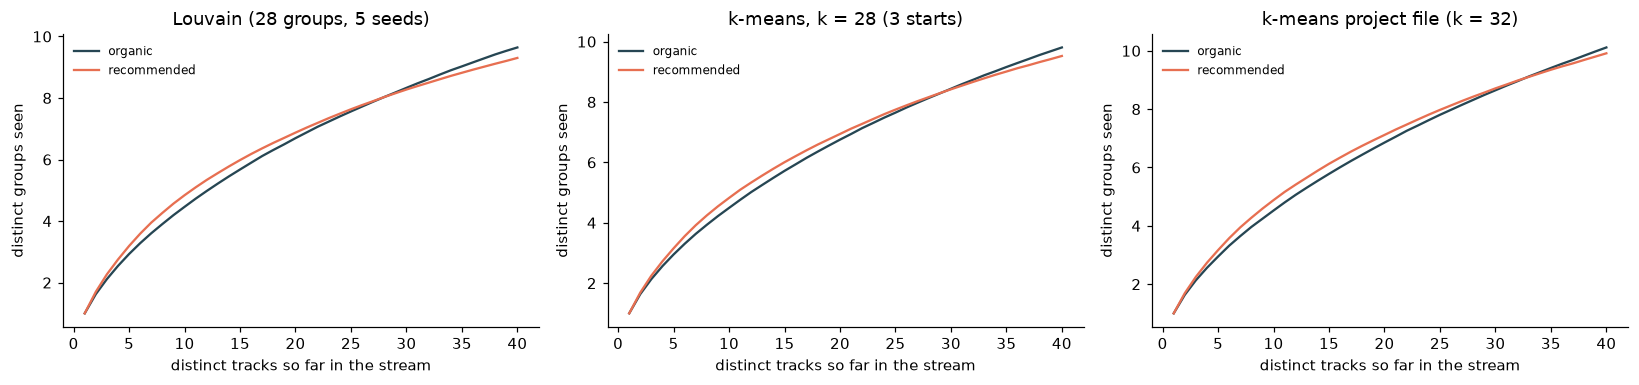

wrote RQ4_pipeline/main_question_results.csv, main_question_sample_size.csv, main_question_discovery.csv


In [7]:
ITEMS = samples[MAIN]; nW = ITEMS.shape[2] // WIN; wlab = [f"{w * WIN + 1}-{(w + 1) * WIN}" for w in range(nW)]
def cum_distinct(items, lab, K):
    G = lab[items].astype(np.int64); U, _, n = G.shape; seen = np.zeros((U, 2, K), bool); out = np.empty((U, 2, n))
    for j in range(n): np.put_along_axis(seen, G[:, :, j:j + 1], True, axis=2); out[:, :, j] = seen.sum(-1)
    return out
curves, rows = {}, []
for dname in [f"Louvain ({K_MATCH} groups, 5 seeds)", f"k-means, k = {K_MATCH} (3 starts)", "k-means project file (k = 32)"]:
    runs, K = DEFS[dname]; CD = np.mean([cum_distinct(ITEMS, lab, K) for lab in runs], axis=0); curves[dname] = CD
    for w in range(nW):
        a, b = w * WIN - 1, (w + 1) * WIN - 1
        new = {j: CD[:, j, b] - (CD[:, j, a] if a >= 0 else 0) for j in (0, 1)}     # j: 0 = recommended, 1 = organic
        rows.append(dict(definition=dname, window=wlab[w], organic_new=new[1].mean(), recommended_new=new[0].mean(), P=((new[0] > new[1]) + 0.5 * (new[0] == new[1])).mean()))
disc = pd.DataFrame(rows); print("new groups first seen in each window of 10 tracks (mean per user):"); print(disc.to_string(index=False, float_format=lambda x: f"{x:.2f}"))
fig, ax = plt.subplots(1, len(curves), figsize=(15, 3.6), sharey=False); xx = np.arange(1, ITEMS.shape[2] + 1)
for a_, (dname, CD) in zip(ax, curves.items()):
    a_.plot(xx, CD[:, 1].mean(0), color=REAL, label="organic"); a_.plot(xx, CD[:, 0].mean(0), color=ACC, label="recommended")
    a_.set(title=dname, xlabel="distinct tracks so far in the stream", ylabel="distinct groups seen"); a_.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
res.drop(columns="direction").to_csv(OUT / "main_question_results.csv", index=False); sens.to_csv(OUT / "main_question_sample_size.csv", index=False); disc.to_csv(OUT / "main_question_discovery.csv", index=False)
print("wrote RQ4_pipeline/main_question_results.csv, main_question_sample_size.csv, main_question_discovery.csv")

### 5.1 Reading the discovery curves

**Recommended listening starts more varied and then returns to groups it has already played, with either definition.** In the first 10 tracks, recommended listening reaches more Louvain groups than organic listening (4.84 against 4.46; P = 0.57). In every later window it adds fewer new groups (2.03 / 1.40 / 1.03 against 2.23 / 1.63 / 1.31; P = 0.46, 0.45, 0.43).
k-means at the same number of groups gives almost identical numbers (first window 4.82 against 4.49, P = 0.55; then P = 0.47, 0.45, 0.44). The early-versus-late finding of `RQ4_extension/03` is a property of the listening, not of the clustering algorithm.

## 6. Summary and limitations
**What this adds to RQ4 and to the main question.**
1. **The main finding holds with Louvain groups.** Recommended listening covers fewer Louvain groups than organic listening for the same users (P(recommended > organic) 0.43 to 0.47 for distinct groups, entropy and novel-group share, all intervals below 0.5, all five seeds), while it covers more artists (P = 0.82).
2. **The effect is as large as with k-means at the same number of groups** (differences in P of at most 0.02, smaller than between k-means starts), it is at least as strong on the graph tracks where Louvain groups need no vote, and it is stronger without the most popular tracks.
3. **Same dependence on the length of listening.** Little or no difference for the first 30 tracks, clear narrowing for 100. Recommended listening starts more varied and then returns to groups already played, under both algorithms.
4. Together with `RQ4_extension/03`, the narrowing now holds for k = 8 to 64, soft memberships, listening-based genres, clustering-free spread measures and **two clustering algorithms**.

**Limitations.**
- *Same users and sample rules as `RQ4_extension/03`* (at least 40 distinct tracks per stream after the 60-day warm-up; 54% of users in the main sample). The popularity-trimmed sample has only 890 users.
- *Louvain groups outside the 50,000 graph tracks come from a vote* (97.5% accurate on held-out graph tracks). The graph-only sample shows the result does not depend on it.
- *Effects are small*: about a third of a group out of 9 to 10 for 40 tracks.
- *Associations only*: the data cannot say why recommended listening is narrower.